# Parametric study: feed-step time of a CO₂ VSA cycle

This notebook sweeps one parameter of a deck and plots how the cycle's KPIs respond.

The deck is `Perez2019_A.json`, one of the example decks shipped with the package: a four-step CO₂ vacuum swing adsorption cycle (feed, blowdown, evacuation, pressurisation) with CO₂ tracked as the product in its KPI configuration. Any deck file works the same way.

To keep the notebook quick, each run is capped at 40 cycles and the cyclic-steady-state check (the deck's own per-component mass-balance check) is allowed from cycle 10 instead of the deck's 100. The table reports whether each run reached cyclic steady state; for a real study, give the runs more cycles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skarstrom

plt.rcParams["figure.dpi"] = 80
print("skarstrom", skarstrom.__version__)

skarstrom 0.1.0


## Load the deck and find the parameter

`parameters(tunable_only=True)` lists the numeric model values with suggested bounds. Each has a stable `path` (by ID) and an `alias` (by display name); either can be used to read or set it.

In [2]:
base = skarstrom.Simulation(skarstrom.example_path("Perez2019_A.json"))
print("steps:", base.steps)
print("components:", base.components)
step_params = [p for p in base.parameters(tunable_only=True) if p.path.startswith("step[")]
pd.DataFrame([(p.path, p.alias, p.value, p.unit) for p in step_params], columns=["path", "alias", "value", "unit"])

steps: ['Feed', 'Blowdown', 'Evacuation', 'Pressurisation']
components: ['CarbonDioxide', 'Nitrogen']


,path,alias,value,unit
0,step[1].time,step[Feed].time,99.0,s
1,step[2].time,step[Blowdown].time,19.0,s
2,step[3].time,step[Evacuation].time,57.0,s
3,step[4].time,step[Pressurisation].time,30.0,s


In [3]:
feed = base.steps[0]
path = f"step[{feed}].time"            # the alias; "step[1].time" is the same parameter
base["css.min_cycles"] = 10
base["cycle.number_of_cycles"] = 40
t0 = base[path]
print(f"{path} = {t0} s")

step[Feed].time = 99.0 s


## Sweep

Each point runs an independent copy of the deck, so the base deck is never modified.

In [4]:
rows = []
for t in np.linspace(0.6 * t0, 1.4 * t0, 5):
    sim = base.copy()
    sim[path] = float(t)
    result = sim.run()
    k = sim.kpis(cycle=-1)[0]
    rows.append({
        "feed time [s]": t,
        "status": result.status,
        "cycles": result.cycles_run,
        "purity [-]": k.purity,
        "recovery [-]": k.recovery,
        "productivity [kg/(kg s)]": k.productivity_mass,
    })
study = pd.DataFrame(rows)
pd.set_option("display.float_format", "{:.4g}".format)
study

,feed time [s],status,cycles,purity [-],recovery [-],productivity [kg/(kg s)]
0,59.4,completed,40,0.9674,0.6817,3.395e-05
1,79.2,completed,40,0.9805,0.6833,3.868e-05
2,99,completed,40,0.9895,0.6804,4.22e-05
3,118.8,completed,40,0.9958,0.6757,4.492e-05
4,138.6,reached_css,39,1,0.6634,4.657e-05


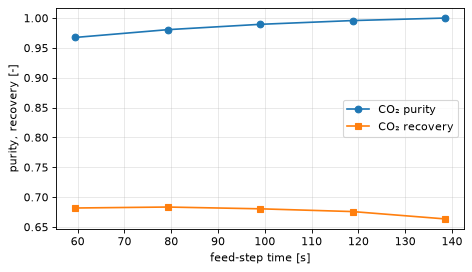

In [5]:
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(study["feed time [s]"], study["purity [-]"], "o-", label="CO₂ purity")
ax1.plot(study["feed time [s]"], study["recovery [-]"], "s-", label="CO₂ recovery")
ax1.set_xlabel("feed-step time [s]")
ax1.set_ylabel("purity, recovery [-]")
ax1.legend(loc="center right")
ax1.grid(alpha=0.3)
fig.tight_layout()

## A closer look at one run

Results are NumPy arrays: here the CO₂ mole fraction at the top of the bed over the last cycle of the longest feed time, and the axial CO₂ loading profile at the end of its feed step.

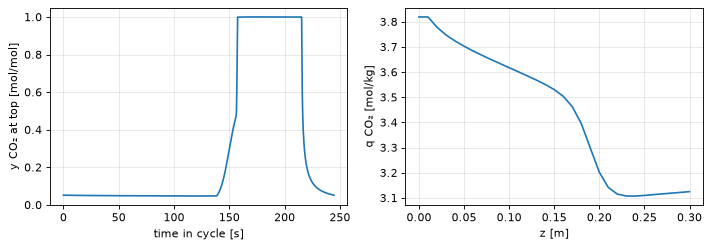

In [6]:
y = sim.series("mole_fraction", "CarbonDioxide", location="top")
prof = sim.profile("adsorbed_concentration", "CarbonDioxide", step=0)
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2))
a.plot(y.time, y.values)
a.set_xlabel("time in cycle [s]"); a.set_ylabel(f"y CO₂ at top [{y.unit}]")
b.plot(prof.z, prof.values[-1])
b.set_xlabel("z [m]"); b.set_ylabel(f"q CO₂ [{prof.unit}]")
for ax in (a, b):
    ax.grid(alpha=0.3)
fig.tight_layout()